# Passo 5b — Homografia: da imagem para o campo visto de cima / dimensões do campo

**Objetivo:** converter posições na imagem (píxeis) em posições reais no campo (metros), para avaliar foras de jogo e se uma falta ocorreu dentro da grande área.

**Método:**
1. Identificar no frame pontos do campo com posição real conhecida (cantos das áreas, linha de baliza, etc.).
2. Com pelo menos 4 correspondências imagem ↔ campo, calcular a **homografia**: uma matriz 3×3 que converte qualquer ponto da imagem para metros.
3. Aplicar a homografia aos pés dos jogadores, árbitros e à bola, e desenhar um **radar** (vista de cima).

São testadas duas formas de obter os pontos: **automática** (modelo YOLOv8-Pose treinado no Passo 5) e **manual**.

## 5.0 Modelos, geometria do campo e funções auxiliares

In [21]:
from pathlib import Path
from ultralytics import YOLO
import cv2, numpy as np, matplotlib.pyplot as plt, shutil

BASE = Path(r"C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS")
CAM_JOG   = BASE / "treinos" / "players_ball_v1" / "weights" / "jogadores_best.pt"
CAM_CAMPO = BASE / "treinos" / "campo_v1" / "weights" / "campo_best.pt"
print("Jogadores existe?", CAM_JOG.exists(), "| Campo existe?", CAM_CAMPO.exists())

modelo_jog   = YOLO(str(CAM_JOG))
modelo_campo = YOLO(str(CAM_CAMPO))
videos = sorted((BASE / "videos").glob("*.mp4"))
PASTA_SAIDA = BASE / "resultados" / "passo5"; PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# ---- Geometria do campo (metros) e os 32 pontos, na ordem do dataset ----
L, W = 105.0, 68.0                                          # Estádio Municipal de Braga: 105 x 68 m
PBW, PBL, GBW, GBL, R, PS = 40.32, 16.5, 18.32, 5.5, 9.15, 11.0
CAMPO = np.array([
    (0, 0), (0, (W-PBW)/2), (0, (W-GBW)/2), (0, (W+GBW)/2), (0, (W+PBW)/2), (0, W),   # 1-6  linha de baliza esq.
    (GBL, (W-GBW)/2), (GBL, (W+GBW)/2),                                               # 7-8  pequena área esq.
    (PS, W/2),                                                                        # 9    penálti esq.
    (PBL, (W-PBW)/2), (PBL, (W-GBW)/2), (PBL, (W+GBW)/2), (PBL, (W+PBW)/2),           # 10-13 grande área esq.
    (L/2, 0), (L/2, W/2-R), (L/2, W/2+R), (L/2, W),                                   # 14-17 meio-campo
    (L-PBL, (W-PBW)/2), (L-PBL, (W-GBW)/2), (L-PBL, (W+GBW)/2), (L-PBL, (W+PBW)/2),   # 18-21 grande área dir.
    (L-PS, W/2),                                                                      # 22   penálti dir.
    (L-GBL, (W-GBW)/2), (L-GBL, (W+GBW)/2),                                           # 23-24 pequena área dir.
    (L, 0), (L, (W-PBW)/2), (L, (W-GBW)/2), (L, (W+GBW)/2), (L, (W+PBW)/2), (L, W),   # 25-30 linha de baliza dir.
    (L/2-R, W/2), (L/2+R, W/2),                                                       # 31-32 círculo central
], dtype=np.float32)

# linhas do campo (em metros) para verificação visual
SEGMENTOS = [
    [(0, 0), (0, W)],
    [(0, (W-PBW)/2), (PBL, (W-PBW)/2), (PBL, (W+PBW)/2), (0, (W+PBW)/2)],
    [(0, (W-GBW)/2), (GBL, (W-GBW)/2), (GBL, (W+GBW)/2), (0, (W+GBW)/2)],
    [(0, 0), (L, 0)], [(0, W), (L, W)], [(L/2, 0), (L/2, W)],
]

# ---- funções auxiliares ----
def para_campo(pontos, H):
    p = np.array(pontos, dtype=np.float32).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(p, H).reshape(-1, 2)

def para_imagem(pontos_m, H):
    p = np.array(pontos_m, dtype=np.float32).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(p, np.linalg.inv(H)).reshape(-1, 2).astype(np.int32)

def desenhar_linhas(frame, H, cor=(255, 0, 255)):
    img = frame.copy()
    for seg in SEGMENTOS:
        cv2.polylines(img, [para_imagem(seg, H)], False, cor, 3)
    return img

def mostrar(img, titulo, grelha=False):
    fig, ax = plt.subplots(figsize=(18 if grelha else 16, 10 if grelha else 9))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(titulo)
    if grelha:
        ax.set_xticks(range(0, img.shape[1], 100)); ax.set_yticks(range(0, img.shape[0], 50))
        ax.grid(color="yellow", alpha=0.35); ax.tick_params(labelsize=7)
    else:
        ax.axis("off")
    plt.show()

# frame de teste: meio do primeiro vídeo
video = videos[0]
cap = cv2.VideoCapture(str(video))
cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
ok, frame = cap.read(); cap.release()
print(f"Frame de teste: {video.name} ({frame.shape[1]}x{frame.shape[0]})")

Jogadores existe? True | Campo existe? True
Frame de teste: J1-Braga-Estrela_1-0.mp4 (1920x1080)


## 5.1 Método automático (modelo de pontos-chave)
O modelo YOLOv8-Pose deteta os pontos do campo; usam-se os que têm confiança > 0,5 e calcula-se a homografia com RANSAC.
Para validar, as linhas do campo são projetadas de volta para a imagem (magenta): se coincidirem com as linhas reais, a homografia está correta.

Pontos fiáveis: 11 de 32 -> [1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 13]


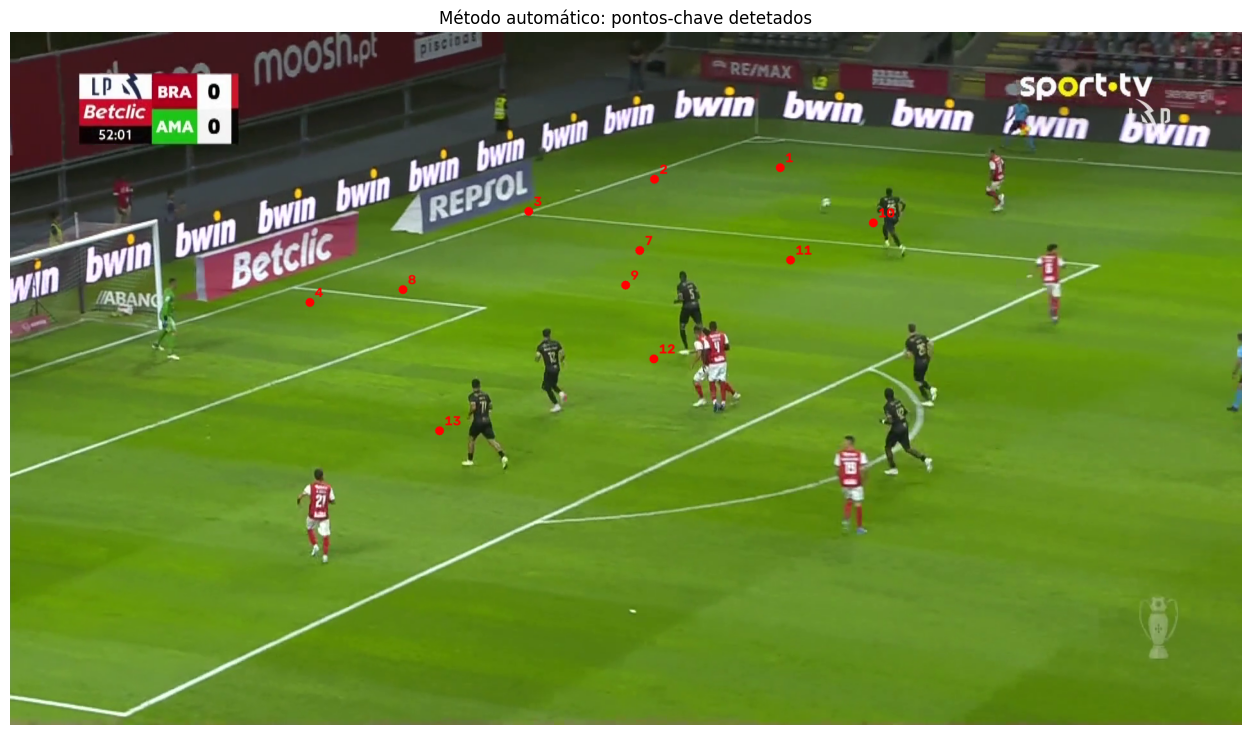

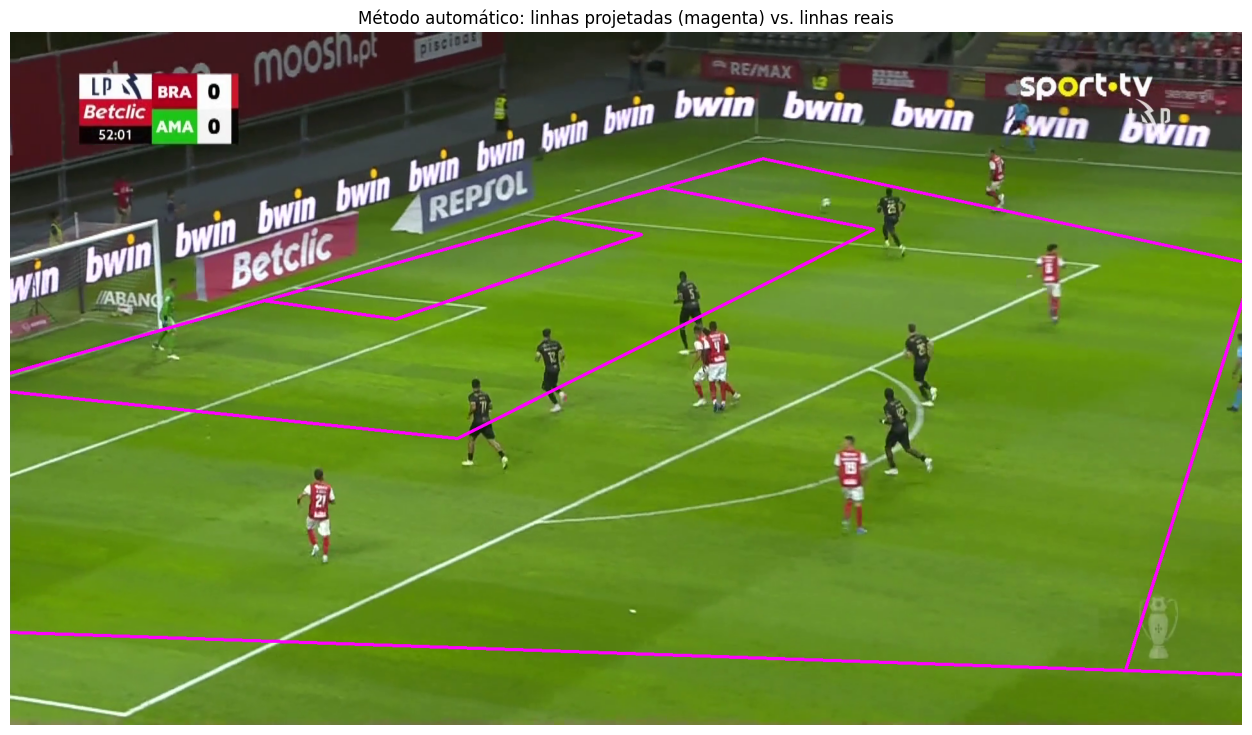

In [22]:
r = modelo_campo(frame, conf=0.3, verbose=False)[0]
kp  = r.keypoints.xy[0].cpu().numpy()
kpc = r.keypoints.conf[0].cpu().numpy()
bons = kpc > 0.5
print(f"Pontos fiáveis: {bons.sum()} de 32 ->", (np.where(bons)[0] + 1).tolist())

H_auto, _ = cv2.findHomography(kp[bons], CAMPO[bons], cv2.RANSAC, 5.0)

img = frame.copy()
for i, (x, y) in enumerate(kp):
    if bons[i]:
        cv2.circle(img, (int(x), int(y)), 7, (0, 0, 255), -1)
        cv2.putText(img, str(i + 1), (int(x) + 8, int(y) - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
mostrar(img, "Método automático: pontos-chave detetados")
mostrar(desenhar_linhas(frame, H_auto), "Método automático: linhas projetadas (magenta) vs. linhas reais")

### Resultado do método automático
Alguns pontos são detetados sobre as linhas corretas, mas outros aparecem na relva sem linha correspondente. As linhas projetadas **não coincidem** com as linhas reais, ou seja, a homografia automática está errada.

**Causa:** diferença de domínio. O modelo foi treinado com imagens de câmara tática (Bundesliga, plano largo e alto), e os vídeos da FootAR são transmissões televisivas (ângulo mais baixo, mais zoom).
**Solução definitiva:** treinar com o dataset de campo da FootAR (frames da Liga Portugal) ou anotar frames destes vídeos e afinar o modelo.
**Solução para o protótipo:** calibração manual (5.2).

## 5.2 Método manual (calibração com 4 pontos)
Marcam-se manualmente 4 cruzamentos de linhas visíveis no frame, cuja posição real é conhecida:

| Ponto | Onde está | Nº |
|---|---|---|
| A | linha de baliza ∩ lateral da pequena área | 3 |
| B | canto da pequena área (lado do campo) | 7 |
| C | linha de baliza ∩ lateral da grande área | 2 |
| D | canto da grande área (lado do campo) | 10 |

A grelha amarela (em píxeis) ajuda a ajustar as coordenadas até os pontos ficarem exatamente nos cruzamentos.

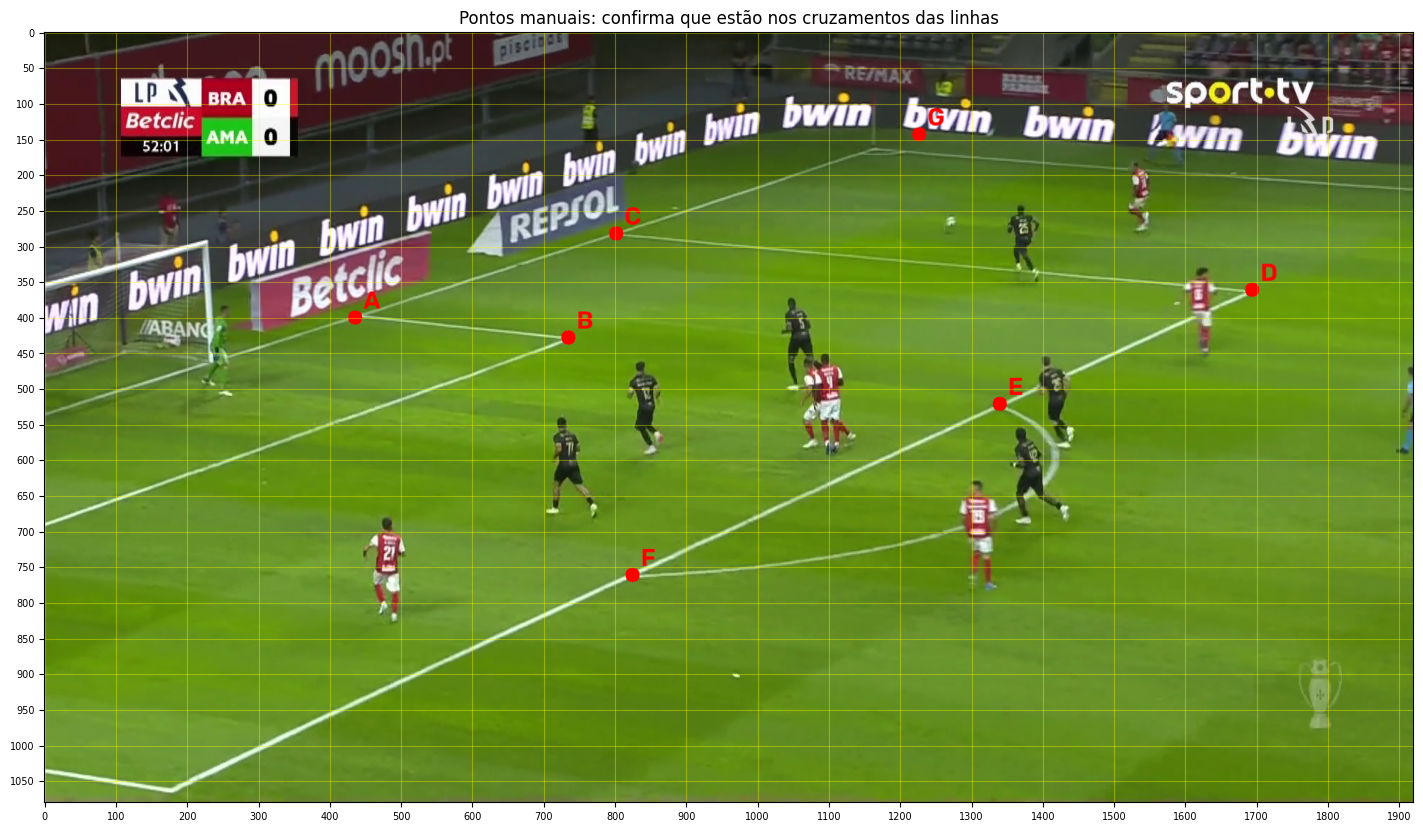

In [ ]:
# (píxeis na imagem)  ->  (metros no campo)
# AJUSTA os píxeis olhando para a grelha
MANUAL = [
    ((436, 400),  (0,    (W-GBW)/2)),        # A: linha de baliza x lateral da pequena área
    ((735, 428),  (GBL,  (W-GBW)/2)),        # B: canto da pequena área
    ((802, 282),  (0,    (W-PBW)/2)),        # C: linha de baliza x lateral da grande área
    ((1694, 361), (PBL,  (W-PBW)/2)),        # D: canto da grande área
    ((1340, 521), (PBL,  W/2 - 7.31)),       # E: meia-lua toca a frente da grande área (lado de cima)
    ((825, 761),  (PBL,  W/2 + 7.31)),       # F: meia-lua toca a frente da grande área (lado de baixo)
    ((1227, 143), (0,    0)),                # G: canto do campo (bandeirola, lado de cima)
]

img = frame.copy()
for i, ((x, y), _) in enumerate(MANUAL):
    letra = "ABCDEFG"[i]
    cv2.circle(img, (x, y), 10, (0, 0, 255), -1)
    cv2.putText(img, letra, (x + 12, y - 12), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)
mostrar(img, "Pontos manuais: confirma que estão nos cruzamentos das linhas", grelha=True)

Ponto A: erro = 0.12 m
Ponto B: erro = 0.42 m
Ponto C: erro = 0.55 m
Ponto D: erro = 0.19 m
Ponto E: erro = 0.12 m
Ponto F: erro = 0.26 m
Ponto G: erro = 0.33 m


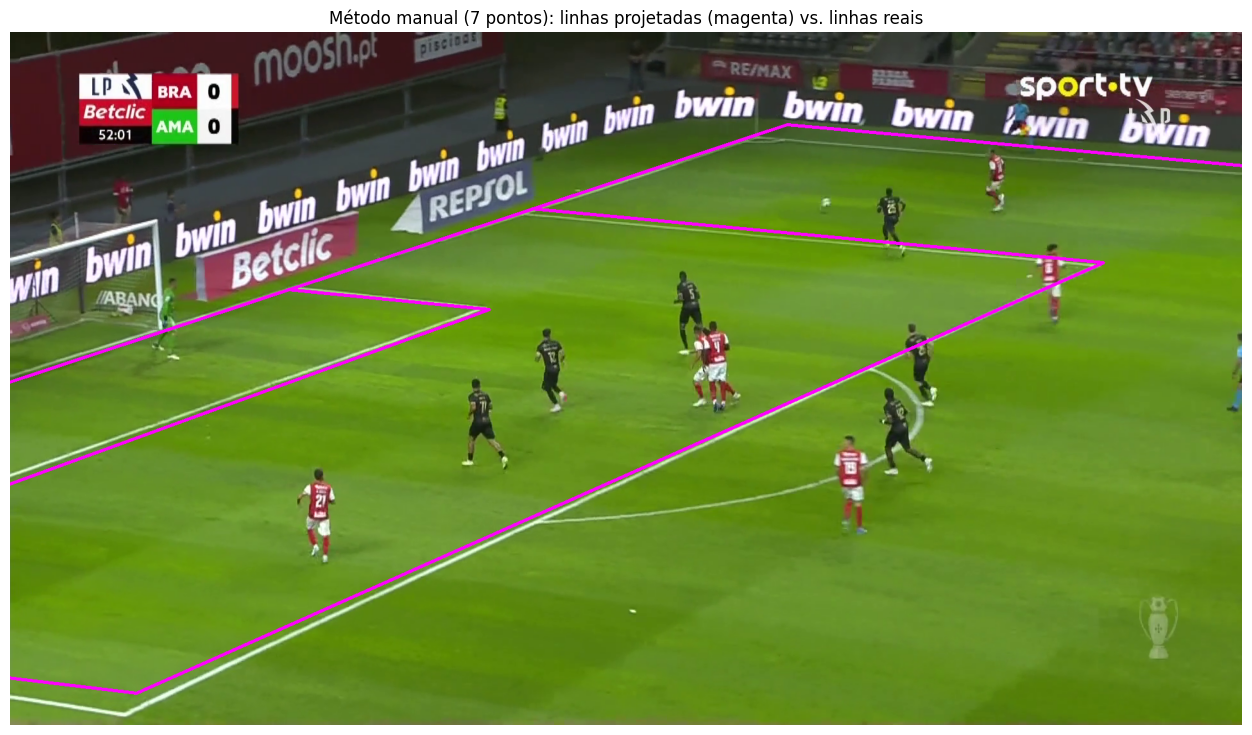

In [24]:
src = np.array([p for p, _ in MANUAL], dtype=np.float32)
dst = np.array([m for _, m in MANUAL], dtype=np.float32)
H, _ = cv2.findHomography(src, dst, 0)        # usa todos os pontos (mínimos quadrados)

# erro de cada ponto: onde a homografia o põe vs. onde devia estar (em metros)
erro = np.linalg.norm(para_campo(src, H) - dst, axis=1)
for i, e in enumerate(erro):
    print(f"Ponto {'ABCDEFG'[i]}: erro = {e:.2f} m")

mostrar(desenhar_linhas(frame, H), "Método manual (7 pontos): linhas projetadas (magenta) vs. linhas reais")

### Resultado da calibração manual (7 pontos)
| Ponto | Descrição | Erro (m) |
|---|---|---|
| A | linha de baliza × lateral da pequena área | 0,12 |
| B | canto da pequena área | 0,42 |
| C | linha de baliza × lateral da grande área | 0,55 |
| D | canto da grande área | 0,19 |
| E | meia-lua × frente da grande área (cima) | 0,12 |
| F | meia-lua × frente da grande área (baixo) | 0,26 |
| G | canto do campo | 0,33 |

- Com 7 pontos distribuídos por todo o frame e as **medidas oficiais FIFA**, as linhas projetadas coincidem com as linhas reais em todo o campo visível.
- Erro médio ≈ 0,3 m e máximo 0,55 m, precisão suficiente para posicionar jogadores (cuja largura é ~0,5 m).
- Lições: (1) os pontos de calibração devem estar **distribuídos por toda a imagem**, para evitar extrapolação; (2) a geometria do campo tem de usar **as dimensões reais**.
- **Limitação:** esta homografia só é válida para este frame. Quando a câmara se move, é preciso recalcular (com o modelo de pontos-chave treinado em dados da Liga Portugal, ou propagando a calibração com o movimento da câmara).

## 5.3 Radar: posições no campo visto de cima
Para cada pessoa usa-se o ponto dos pés (centro da base da caixa); para a bola, o centro da caixa. As posições são convertidas para metros com a homografia manual.

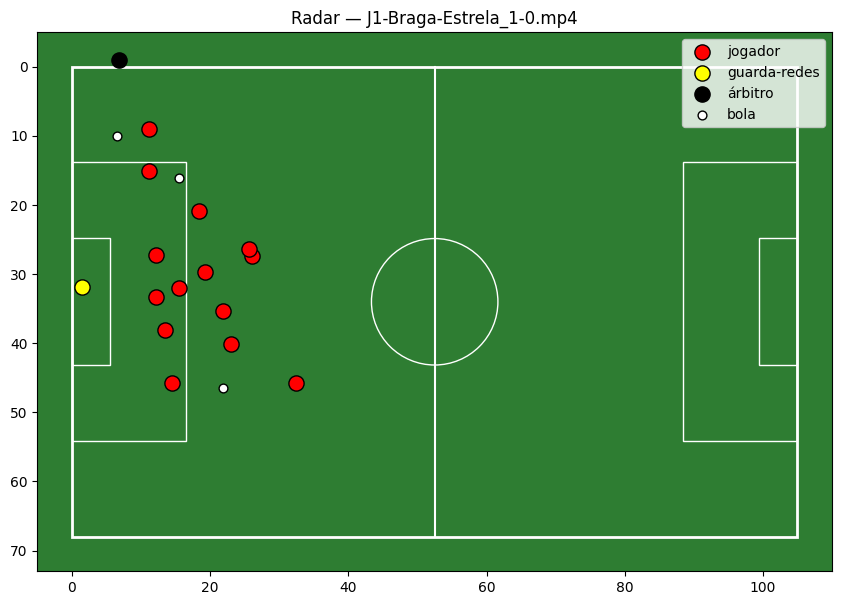

In [26]:
def desenhar_campo(ax):
    ax.set_facecolor("#2e7d32")
    ax.add_patch(plt.Rectangle((0, 0), L, W, fill=False, ec="w", lw=2))
    for x0 in (0, L - PBL):
        ax.add_patch(plt.Rectangle((x0, (W-PBW)/2), PBL, PBW, fill=False, ec="w"))
    for x0 in (0, L - GBL):
        ax.add_patch(plt.Rectangle((x0, (W-GBW)/2), GBL, GBW, fill=False, ec="w"))
    ax.add_patch(plt.Circle((L/2, W/2), R, fill=False, ec="w"))
    ax.plot([L/2, L/2], [0, W], "w-")
    ax.set_xlim(-5, L + 5); ax.set_ylim(W + 5, -5); ax.set_aspect("equal")

d = modelo_jog(frame, conf=0.3, imgsz=1280, verbose=False)[0]
caixas = d.boxes.xyxy.cpu().numpy(); cls = d.boxes.cls.cpu().numpy().astype(int)
pes = np.column_stack([(caixas[:, 0] + caixas[:, 2]) / 2,
                       np.where(cls == 0, (caixas[:, 1] + caixas[:, 3]) / 2, caixas[:, 3])])
pos = para_campo(pes, H)

fig, ax = plt.subplots(figsize=(12, 7))
desenhar_campo(ax)
cores = {0: "white", 1: "yellow", 2: "red", 3: "black"}
nomes = {0: "bola", 1: "guarda-redes", 2: "jogador", 3: "árbitro"}
for c in (2, 1, 3, 0):
    m = cls == c
    if m.any():
        ax.scatter(pos[m, 0], pos[m, 1], c=cores[c], s=40 if c == 0 else 120,
                   edgecolors="k", label=nomes[c], zorder=3)
ax.legend(loc="upper right"); ax.set_title(f"Radar — {video.name}")
plt.savefig(PASTA_SAIDA / f"{video.stem}_radar.png", dpi=120, bbox_inches="tight")
plt.show()

## 5.4 Conclusões
- **Método automático:** as linhas projetadas não coincidem com as reais. O modelo de pontos-chave (treinado em câmara tática) não generaliza para as transmissões da Liga Portugal.
- **Método manual (7 pontos, medidas FIFA):** as linhas coincidem em todo o campo visível, com erro médio ≈ 0,3 m.
- **Radar:** as posições são coerentes com o vídeo. O guarda-redes está junto à baliza esquerda, os jogadores estão à volta da grande área, e o árbitro assistente aparece junto à linha lateral (fora do campo, como esperado).
- **Próximo passo:** com as posições em metros e a separação das equipas, é possível calcular a **linha de fora de jogo**.

# Passo 6 — Linha de fora de jogo

**Regra (simplificada):** um atacante está em posição de fora de jogo se, no momento do passe, estiver no meio-campo adversário e mais perto da linha de baliza do que a bola e do que o **penúltimo defensor** (o guarda-redes conta como defensor).

**Método:**
1. Classificar as equipas pela cor (K-Means em CIELAB, como no Passo 4).
2. Identificar a equipa que defende (aqui, a que defende a baliza da esquerda: Estrela, de preto).
3. Converter as posições para metros (homografia) e encontrar o **penúltimo defensor**: o 2.º com menor x, contando com o guarda-redes.
4. Marcar a **linha de fora de jogo** e assinalar os atacantes para lá dela.

**Nota:** a decisão só faz sentido no frame exato do passe. Aqui demonstra-se o cálculo num frame do clip.

## 6.1 Classificação das equipas
As equipas são separadas pela cor da camisola (cor mediana em CIELAB) com K-Means (k = 2), usando jogadores de 10 frames do vídeo.
A equipa com menor luminosidade (L) é a de equipamento escuro (Estrela da Amadora).

In [28]:
from sklearn.cluster import KMeans

def cor_lab(frame, caixa):
    x1, y1, x2, y2 = caixa.astype(int)
    h, w = y2 - y1, x2 - x1
    crop = frame[max(0, y1 + int(0.20*h)): y1 + int(0.45*h), max(0, x1 + int(0.25*w)): x2 - int(0.25*w)]
    if crop.size == 0:
        return None
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    nao_relva = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255)) == 0
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB)[nao_relva]
    return None if len(lab) < 10 else np.median(lab, axis=0)

cap = cv2.VideoCapture(str(video)); total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
amostras = []
for idx in np.linspace(0, total - 1, 10).astype(int):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, f = cap.read()
    if not ok: continue
    rr = modelo_jog(f, conf=0.3, imgsz=1280, verbose=False)[0]
    for cx, cc in zip(rr.boxes.xyxy.cpu().numpy(), rr.boxes.cls.cpu().numpy().astype(int)):
        if cc == 2:
            v = cor_lab(f, cx)
            if v is not None: amostras.append(v)
cap.release()

kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit(np.array(amostras))
EQ_ESCURA = int(np.argmin(kmeans.cluster_centers_[:, 0]))
print(f"{len(amostras)} jogadores | equipa escura (Estrela) = grupo {EQ_ESCURA}")

def equipa(frame, caixa):
    v = cor_lab(frame, caixa)
    return -1 if v is None else int(kmeans.predict([v])[0])

128 jogadores | equipa escura (Estrela) = grupo 1


## 6.2 Mapa dos grupos e centróides
Cada ponto é um jogador (cor mediana da camisola em CIELAB): eixo **a** (verde ← → vermelho) e eixo **L** (escuro → claro).
O contorno indica o grupo atribuído pelo K-Means e as **estrelas** marcam os centróides (cor média de cada equipa).

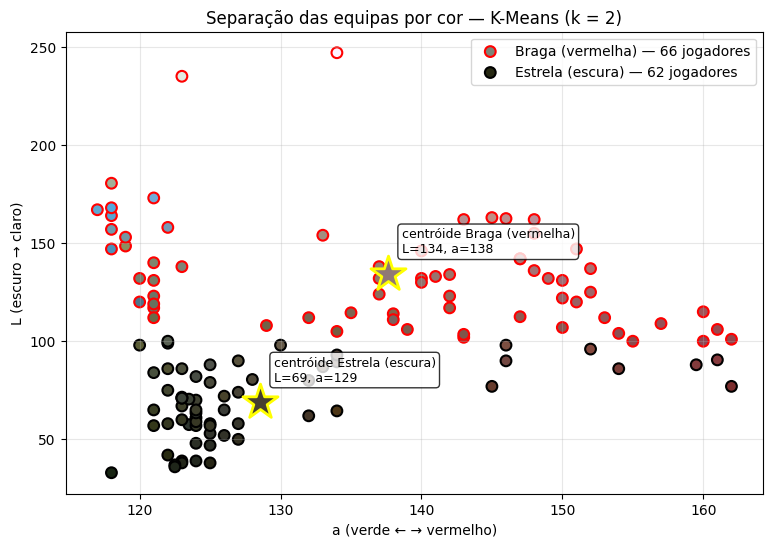

Distância entre centróides (Lab): 66.2


In [29]:
X = np.array(amostras); grupos = kmeans.labels_; centros = kmeans.cluster_centers_
cor_real   = cv2.cvtColor(X.astype(np.uint8).reshape(-1, 1, 3), cv2.COLOR_LAB2RGB).reshape(-1, 3) / 255
cor_centro = cv2.cvtColor(centros.astype(np.uint8).reshape(-1, 1, 3), cv2.COLOR_LAB2RGB).reshape(-1, 3) / 255
contorno = {EQ_ESCURA: "black", 1 - EQ_ESCURA: "red"}
nome     = {EQ_ESCURA: "Estrela (escura)", 1 - EQ_ESCURA: "Braga (vermelha)"}

fig, ax = plt.subplots(figsize=(9, 6))
for g in (0, 1):
    m = grupos == g
    ax.scatter(X[m, 1], X[m, 0], c=cor_real[m], edgecolors=contorno[g], linewidths=1.5, s=60,
               label=f"{nome[g]} — {m.sum()} jogadores")
    ax.scatter(centros[g, 1], centros[g, 0], marker="*", s=700, c=[cor_centro[g]], edgecolors="yellow", linewidths=2, zorder=5)
    ax.annotate(f"centróide {nome[g]}\nL={centros[g,0]:.0f}, a={centros[g,1]:.0f}", (centros[g, 1], centros[g, 0]),
                xytext=(10, 15), textcoords="offset points", fontsize=9, bbox=dict(boxstyle="round", fc="white", alpha=0.8))
ax.set_xlabel("a (verde ← → vermelho)"); ax.set_ylabel("L (escuro → claro)")
ax.set_title("Separação das equipas por cor — K-Means (k = 2)"); ax.grid(alpha=0.3); ax.legend()
plt.show()
print(f"Distância entre centróides (Lab): {np.linalg.norm(centros[0] - centros[1]):.1f}")

## 6.3 Linha de fora de jogo
O Braga (vermelho) ataca a baliza da esquerda e o Estrela (preto) defende. Em metros, "mais perto da baliza" corresponde a **x menor**.
- **Defensores:** jogadores do Estrela + guarda-redes.
- **Linha de fora de jogo:** posição x do **penúltimo defensor** (2.º menor x).
- **Atacantes para lá da linha:** jogadores do Braga com x menor do que a linha, no meio-campo adversário.

Defensores: 8 | Atacantes: 5 | Linha: x = 11.1 m | Para lá da linha: 1


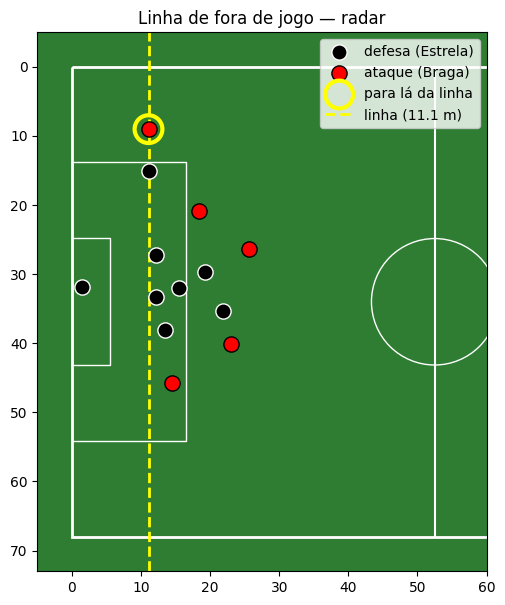

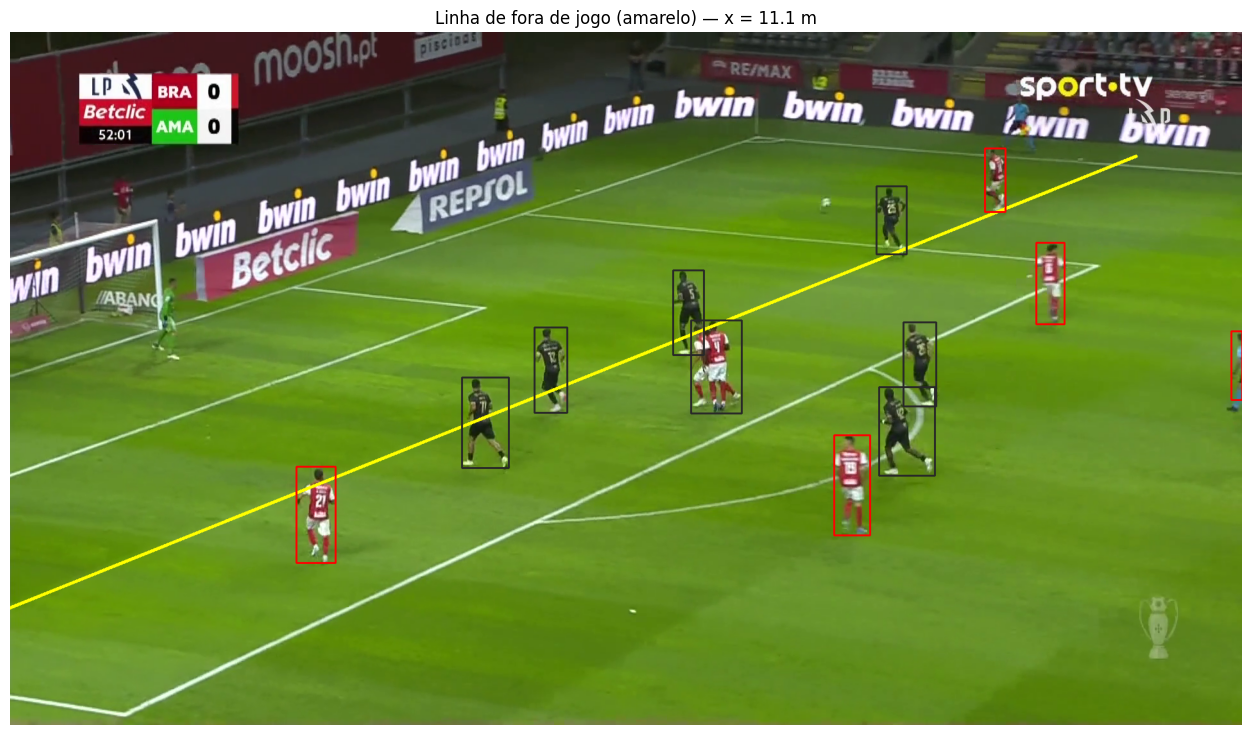

In [30]:
EQ_DEFENDE = EQ_ESCURA
EQ_ATACA   = 1 - EQ_DEFENDE

eq  = np.array([equipa(frame, c) if k == 2 else -1 for c, k in zip(caixas, cls)])
pos = para_campo(pes, H)

defesas   = pos[((cls == 2) & (eq == EQ_DEFENDE)) | (cls == 1)]
atacantes = pos[(cls == 2) & (eq == EQ_ATACA)]
xs = np.sort(defesas[:, 0])
LINHA = xs[1] if len(xs) >= 2 else np.nan
fora = atacantes[(atacantes[:, 0] < LINHA) & (atacantes[:, 0] < L/2)]
print(f"Defensores: {len(defesas)} | Atacantes: {len(atacantes)} | Linha: x = {LINHA:.1f} m | Para lá da linha: {len(fora)}")

# radar
fig, ax = plt.subplots(figsize=(12, 7)); desenhar_campo(ax)
ax.scatter(defesas[:, 0], defesas[:, 1], c="black", s=120, edgecolors="w", label="defesa (Estrela)", zorder=3)
ax.scatter(atacantes[:, 0], atacantes[:, 1], c="red", s=120, edgecolors="k", label="ataque (Braga)", zorder=3)
if len(fora):
    ax.scatter(fora[:, 0], fora[:, 1], s=400, facecolors="none", edgecolors="yellow", lw=3, label="para lá da linha", zorder=4)
ax.axvline(LINHA, color="yellow", ls="--", lw=2, label=f"linha ({LINHA:.1f} m)")
ax.set_xlim(-5, 60); ax.legend(loc="upper right"); ax.set_title("Linha de fora de jogo — radar")
plt.show()

# linha projetada na imagem
img = frame.copy()
cv2.polylines(img, [para_imagem([(LINHA, 0), (LINHA, W)], H)], False, (0, 255, 255), 3)
for (x1, y1, x2, y2), k, e in zip(caixas.astype(int), cls, eq):
    if k == 2 and e >= 0:
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255) if e == EQ_ATACA else (40, 40, 40), 2)
mostrar(img, f"Linha de fora de jogo (amarelo) — x = {LINHA:.1f} m")

### Resultado
- **Linha de fora de jogo:** x = 11,1 m (penúltimo defensor do Estrela; o guarda-redes é o último, em x ≈ 1,5 m).
- A linha projetada na imagem é paralela à linha de baliza e segue a perspetiva da câmara, como as linhas virtuais usadas nas transmissões/VAR, o que confirma a homografia.
- **1 atacante do Braga** aparece ligeiramente para lá da linha (≈ 0,2 m). Esta diferença é **inferior ao erro da homografia (~0,3 m)**, pelo que a situação é **inconclusiva** ("em linha").

**Limitações:**
1. O fora de jogo só se avalia **no instante do passe**; este frame é ilustrativo. É necessário detetar automaticamente o momento do passe (mudança de posse da bola entre jogadores da mesma equipa).
2. Falta verificar a condição "à frente da bola".
3. Erros de classificação (ex.: árbitro detetado como jogador) e a precisão da homografia afetam diretamente a decisão em lances apertados.